
========== GRID OPTIMIZATION RESULTS ==========
Number of Jobs: 100
Number of Processors: 13
Number of Job Sets: 14

Optimized Task Allocation:
Processor 1: 7 jobs
Processor 2: 12 jobs
Processor 3: 8 jobs
Processor 4: 9 jobs
Processor 5: 5 jobs
Processor 6: 4 jobs
Processor 7: 5 jobs
Processor 8: 10 jobs
Processor 9: 9 jobs
Processor 10: 8 jobs
Processor 11: 3 jobs
Processor 12: 11 jobs
Processor 13: 9 jobs

Makespan: 69.466 seconds
Total Transfer Time: 66.294 seconds
Load Balance Score: 95.51 %
Best Fitness: 137.296


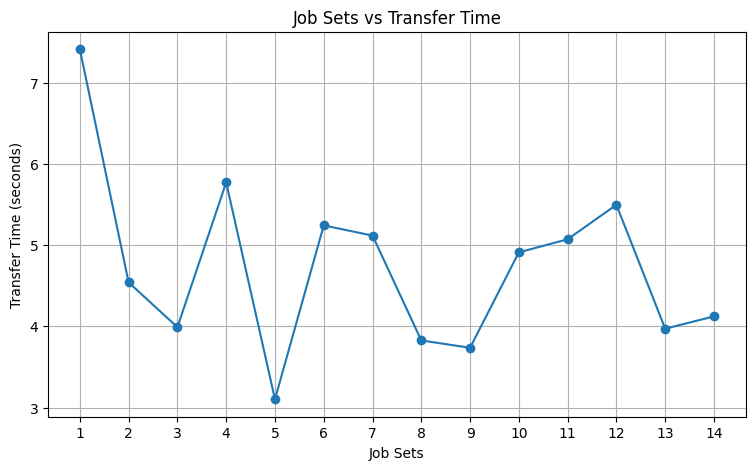

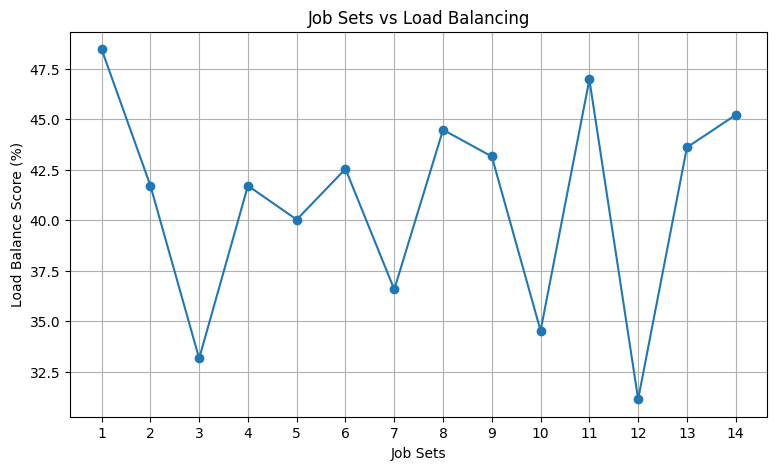

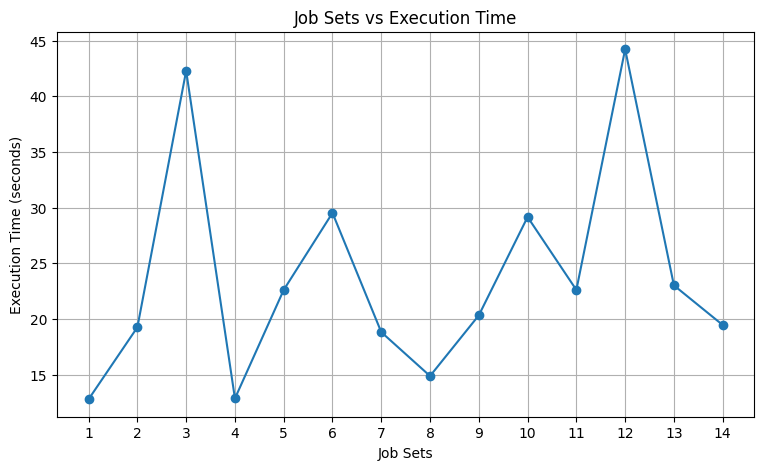

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math

np.random.seed(42)

# ---------------- INPUTS ----------------
NUM_JOBS = 100
NUM_PROCESSORS = 13
NUM_JOBSETS = 14

NESTS = 25
MAX_ITER = 100
PA = 0.25

# Generate heterogeneous processor speeds
speeds = np.random.uniform(0.8, 2.0, NUM_PROCESSORS)

# Generate job workloads and data sizes
workloads = np.random.uniform(5, 20, NUM_JOBS)
data_size = np.random.uniform(1, 10, NUM_JOBS)

# Execution time matrix
execution = workloads[:, None] / speeds[None, :]
execution += np.random.uniform(0.1, 0.5, (NUM_JOBS, NUM_PROCESSORS))

# Transfer time matrix (bandwidth: 50-100 Mbps)
bandwidth = np.random.uniform(50, 100, NUM_PROCESSORS)
transfer = (data_size[:, None] * 8) / bandwidth[None, :]

# Divide jobs into 14 job sets
jobsets = np.array_split(np.arange(NUM_JOBS), NUM_JOBSETS)


# ---------------- FITNESS FUNCTION ----------------
def fitness(solution):
    loads = np.zeros(NUM_PROCESSORS)

    for job in range(NUM_JOBS):
        processor = solution[job]
        loads[processor] += execution[job, processor]

    makespan = np.max(loads)
    transfer_time = np.sum(transfer[np.arange(NUM_JOBS), solution])
    imbalance = np.std(loads)

    return makespan + transfer_time + 0.5 * imbalance


# ---------------- LEVY FLIGHT ----------------
def levy_flight():
    beta = 1.5
    sigma = (
        math.gamma(1 + beta) * math.sin(math.pi * beta / 2)
        / (math.gamma((1 + beta) / 2) * beta * 2 ** ((beta - 1) / 2))
    ) ** (1 / beta)

    u = np.random.normal(0, sigma)
    v = np.random.normal(0, 1)

    return u / (abs(v) ** (1 / beta) + 1e-10)


# ---------------- INITIAL POPULATION ----------------
nests = np.random.randint(
    0, NUM_PROCESSORS, (NESTS, NUM_JOBS)
)

scores = np.array([fitness(nest) for nest in nests])

best_index = np.argmin(scores)
best_solution = nests[best_index].copy()
best_fitness = scores[best_index]

convergence = []


# ---------------- CUCKOO SEARCH ----------------
for iteration in range(MAX_ITER):

    for i in range(NESTS):

        new_solution = nests[i].copy()

        # Lévy-flight-inspired task reassignment
        step = abs(levy_flight()) * 3
        changes = max(1, min(NUM_JOBS, int(step) + 1))

        selected_jobs = np.random.choice(
            NUM_JOBS, changes, replace=False
        )

        for job in selected_jobs:
            new_solution[job] = np.random.randint(NUM_PROCESSORS)

        new_score = fitness(new_solution)

        # Select a random nest
        j = np.random.randint(NESTS)

        if new_score < scores[j]:
            nests[j] = new_solution
            scores[j] = new_score

    # Abandon worst nests
    abandon_count = max(1, int(PA * NESTS))
    worst = np.argsort(scores)[-abandon_count:]

    for index in worst:
        nests[index] = np.random.randint(
            0, NUM_PROCESSORS, NUM_JOBS
        )
        scores[index] = fitness(nests[index])

    # Update global best
    current_best = np.argmin(scores)

    if scores[current_best] < best_fitness:
        best_fitness = scores[current_best]
        best_solution = nests[current_best].copy()

    convergence.append(best_fitness)


# ---------------- FINAL RESULTS ----------------
loads = np.zeros(NUM_PROCESSORS)

for job in range(NUM_JOBS):
    p = best_solution[job]
    loads[p] += execution[job, p]

makespan = np.max(loads)
total_transfer = np.sum(
    transfer[np.arange(NUM_JOBS), best_solution]
)

mean_load = np.mean(loads)
cv = np.std(loads) / (mean_load + 1e-10)
balance_score = 100 / (1 + cv)

print("\n========== GRID OPTIMIZATION RESULTS ==========")
print("Number of Jobs:", NUM_JOBS)
print("Number of Processors:", NUM_PROCESSORS)
print("Number of Job Sets:", NUM_JOBSETS)

print("\nOptimized Task Allocation:")
for i in range(NUM_PROCESSORS):
    assigned = np.where(best_solution == i)[0]
    print(f"Processor {i+1}: {len(assigned)} jobs")

print("\nMakespan:", round(makespan, 3), "seconds")
print("Total Transfer Time:", round(total_transfer, 3), "seconds")
print("Load Balance Score:", round(balance_score, 2), "%")
print("Best Fitness:", round(best_fitness, 3))


# ---------------- JOB SET METRICS ----------------
transfer_values = []
execution_values = []
balance_values = []

for group in jobsets:

    group_loads = np.zeros(NUM_PROCESSORS)
    group_transfer = 0

    for job in group:
        p = best_solution[job]
        group_loads[p] += execution[job, p]
        group_transfer += transfer[job, p]

    group_makespan = np.max(group_loads)

    mean = np.mean(group_loads)
    cv = np.std(group_loads) / (mean + 1e-10)
    group_balance = 100 / (1 + cv)

    transfer_values.append(group_transfer)
    execution_values.append(group_makespan)
    balance_values.append(group_balance)


# ---------------- THREE GRAPHS ----------------
x = np.arange(1, NUM_JOBSETS + 1)

plt.figure(figsize=(9, 5))
plt.plot(x, transfer_values, marker='o')
plt.title("Job Sets vs Transfer Time")
plt.xlabel("Job Sets")
plt.ylabel("Transfer Time (seconds)")
plt.grid(True)
plt.xticks(x)
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(x, balance_values, marker='o')
plt.title("Job Sets vs Load Balancing")
plt.xlabel("Job Sets")
plt.ylabel("Load Balance Score (%)")
plt.grid(True)
plt.xticks(x)
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(x, execution_values, marker='o')
plt.title("Job Sets vs Execution Time")
plt.xlabel("Job Sets")
plt.ylabel("Execution Time (seconds)")
plt.grid(True)
plt.xticks(x)
plt.show()